# 05 - Future spend regression
Predict each customer's total spend in the 6 months after the cutoff (`future_spend`) with Linear Regression, Random Forest and XGBoost, on the 8 selected spend features.

## Why we train on log1p(future_spend)
In TRAIN, 46% of customers spend **0** in the next 6 months, the median is 128 GBP and the maximum is 110,155 GBP. On the raw scale a handful of giant customers would dominate the training error, and the models would mostly learn about them. `log1p(x) = log(1 + x)` squeezes the long tail (100,000 becomes about 11.5) and keeps 0 as 0. After predicting, we go back to GBP with `expm1` and report all errors in GBP.

**Side effect:** the back-transform of an average on the log scale is closer to a *typical* (median-like) customer than to the *average* customer, so GBP predictions come out too low on average. Duan's smearing correction tries to fix that (section 3).

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import config
import spend_models as sm

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

X_train, y_train_log, X_test, y_test, train, test = sm.load_spend_data()
print('Features:', list(X_train.columns))
print(f"Train: mean {train['future_spend'].mean():.1f}, median {train['future_spend'].median():.1f}, zero share {(train['future_spend'] == 0).mean():.1%}")
print(f"Test:  mean {y_test.mean():.1f}, median {y_test.median():.1f}, zero share {(y_test == 0).mean():.1%}")

Features: ['monetary', 'purchase_regularity', 'unique_products', 'frequency', 'seg_Champions', 'avg_gap_days', 'avg_order_value', 'tenure_days']
Train: mean 793.6, median 127.8, zero share 46.1%
Test:  mean 1444.3, median 406.6, zero share 29.8%


## 1. Cross-validation on TRAIN (used to choose the final model)
Random Forest and XGBoost are tuned with a small GridSearchCV on the log target. Then every model is scored with 5-fold out-of-fold CV on TRAIN, both on the log scale and in GBP, without and with smearing. The baselines are scored on TRAIN too.

**Selection rule: lowest CV RMSE in GBP on TRAIN.** The profit rule (Phase 9) multiplies churn probability by predicted spend in GBP, so the GBP error is the metric that matters. The choice uses TRAIN data only.

In [2]:
cv_table, pipelines, best_params = sm.run_train_cv(X_train, y_train_log, train)
cv_table.to_csv(config.TABLES_DIR / 'spend_cv_train.csv', index=False)
print(best_params)
cv_table.round(3)

CV done: Linear Regression
CV done: Linear Regression + smearing


CV done: Random Forest


CV done: Random Forest + smearing


CV done: XGBoost


CV done: XGBoost + smearing
{'Linear Regression': {}, 'Random Forest': {'model__max_depth': 4, 'model__min_samples_leaf': 20}, 'XGBoost': {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 200}}


,model,cv_rmse_log,cv_rmse_gbp,cv_mae_gbp,cv_r2_gbp,cv_mean_predicted
0,Historical-rate baseline,NaN,3989.644,1373.902,-0.263,1981.182
1,Median baseline (train median),NaN,3611.926,786.064,-0.035,127.750
2,Linear Regression,2.728,2830.111,621.813,0.364,424.790
3,Linear Regression + smearing,2.728,61436.451,7106.289,-298.494,7668.311
4,Random Forest,2.736,3154.468,623.091,0.210,267.837
5,Random Forest + smearing,2.736,15743.931,4114.713,-18.668,4682.444
6,XGBoost,2.727,3173.934,625.570,0.201,245.055
7,XGBoost + smearing,2.727,11363.479,3477.073,-9.246,4019.450


In [3]:
final_name = sm.choose_final_model(cv_table)
print('Final spend model (lowest CV RMSE in GBP):', final_name)

Final spend model (lowest CV RMSE in GBP): Linear Regression


**Choice:** Plain **Linear Regression** has the lowest CV RMSE in GBP (2,830) and the best CV R-squared in GBP (0.364). Random Forest (0.210) and XGBoost (0.201) are worse in GBP because trees cannot predict above the largest values they saw, so they miss the few very big spenders that dominate GBP errors. On the **log scale** the three models are tied (CV RMSE 2.727-2.736), which is why the log score alone could not choose. Both baselines are poor on TRAIN (historical-rate R-squared -0.263, median -0.035). Every '+ smearing' row is far worse (R-squared from -9 to -298), so smearing is not selected.

## 2. Test results (GBP)
Every model is refitted on all of TRAIN and scored on TEST. Predictions are capped at the largest `future_spend` seen in TRAIN; `n_capped` counts how many test predictions hit the cap.

In [4]:
test_table, fitted, factors, predictions, cap = sm.fit_and_test(
    pipelines, X_train, y_train_log, X_test, y_test, train, test)
sm.check_leakage_alarm(test_table)
test_table.to_csv(config.TABLES_DIR / 'spend_model_comparison.csv', index=False)
print(f'Cap (train max future_spend): {cap:,.1f} GBP')
print('Smearing factors learned on TRAIN:', {k: round(v, 2) for k, v in factors.items()})
test_table.round(3)

Leakage alarm check: no row above test R2 0.9 (max 0.772)
Cap (train max future_spend): 110,155.1 GBP
Smearing factors learned on TRAIN: {'Linear Regression': 17.94, 'Random Forest': 18.18, 'XGBoost': 16.71}


,model,n_capped,mae,rmse,r2,mae_spenders_only,r2_log_scale,mean_predicted,mean_actual,max_predicted,max_actual
0,Historical-rate baseline,0,1042.424,3212.441,0.772,1055.221,-0.228,1777.996,1444.314,128514.098,183529.65
1,Median baseline (train median),0,1396.624,6852.931,-0.038,1935.182,-0.003,127.750,1444.314,127.750,183529.65
2,Linear Regression,1,1005.588,4169.478,0.616,1397.371,0.262,645.385,1444.314,110155.120,183529.65
3,Linear Regression + smearing,35,5656.092,15339.365,-4.202,7491.023,-0.157,6699.013,1444.314,110155.120,183529.65
4,Random Forest,0,1101.684,6116.204,0.173,1527.633,0.269,479.748,1444.314,9920.338,183529.65
5,Random Forest + smearing,50,6573.051,16640.380,-5.122,8636.107,-0.231,7650.461,1444.314,110155.120,183529.65
6,XGBoost,0,1119.247,6183.903,0.155,1556.250,0.272,425.286,1444.314,10382.205,183529.65
7,XGBoost + smearing,29,5757.829,13937.019,-3.295,7581.114,-0.182,6817.325,1444.314,110155.117,183529.65


**What the test table shows:** The final model (Linear Regression) gets MAE 1,006 GBP, RMSE 4,169 GBP and R-squared 0.616 on TEST. For customers who really spent something, the MAE is 1,397 GBP, which is large compared with a median test spend of 407 GBP. **The historical-rate baseline beats every model on TEST in GBP** (RMSE 3,212, R-squared 0.772), even though it was the *worst* on TRAIN (R-squared -0.263). This is partly seasonal: the baseline averages each customer's past spend, which includes the Christmas peak, and the test window (Jun-Nov) also includes the autumn peak, while the train window (Dec-May) does not. On the log scale (how well customers are ranked) the models are better than the baseline (0.26-0.27 vs -0.23). The mean prediction is 645 GBP vs an actual mean of 1,444 GBP.

## 3. Smearing: before vs after

In [5]:
before_after = test_table[test_table['model'].str.startswith(tuple(sm.MODEL_NAMES))]
before_after[['model', 'mae', 'rmse', 'r2', 'mean_predicted', 'mean_actual', 'n_capped']].round(1)

,model,mae,rmse,r2,mean_predicted,mean_actual,n_capped
2,Linear Regression,1005.6,4169.5,0.6,645.4,1444.3,1
3,Linear Regression + smearing,5656.1,15339.4,-4.2,6699.0,1444.3,35
4,Random Forest,1101.7,6116.2,0.2,479.7,1444.3,0
5,Random Forest + smearing,6573.1,16640.4,-5.1,7650.5,1444.3,50
6,XGBoost,1119.2,6183.9,0.2,425.3,1444.3,0
7,XGBoost + smearing,5757.8,13937.0,-3.3,6817.3,1444.3,29


**Smearing made things much worse here.** The factors learned on TRAIN are about 17-18, so predictions are multiplied by about 18 and the mean prediction jumps to about 6,700 GBP vs an actual 1,444 (R-squared about -4). Smearing assumes the log-scale errors are roughly the same for every customer. Here about half of the customers spend exactly 0, so the log errors are huge and two-sided (CV RMSE about 2.7 on the log scale), and a few large positive errors dominate the average of exp(error). Note also that smearing is only meant to fix the **log-transform bias**; it could never fix the **season mismatch** (train Dec-May vs test Jun-Nov). We report it but do not use it. A better fix for later would be a two-part model: first P(spend > 0), then the amount for spenders.

## 4. Extreme predictions

In [6]:
final_pred = predictions[final_name]
print(f'Final model max prediction (after cap): {final_pred.max():,.1f} GBP')
print(f'Max actual test spend:                  {y_test.max():,.1f} GBP')
print(f'Max train future_spend (cap):           {cap:,.1f} GBP')
print('Top 5 predictions:', sorted(final_pred, reverse=True)[:5])

Final model max prediction (after cap): 110,155.1 GBP
Max actual test spend:                  183,529.6 GBP
Max train future_spend (cap):           110,155.1 GBP
Top 5 predictions: [np.float64(110155.12), np.float64(98141.7829497783), np.float64(88849.91643642567), np.float64(70224.54169734738), np.float64(60616.185520049)]


**No absurd predictions.** The largest final prediction before capping was 118,695 GBP, for a customer who really spent 95,363 GBP and had spent 170,061 GBP before the cutoff, so it is reasonable. It is just above the TRAIN maximum (110,155 GBP), so the cap lowers it to 110,155; this is the only capped value (`n_capped = 1`). The cap stays in the saved model as a safety net for the app.

## 5. Predicted vs actual (final model)

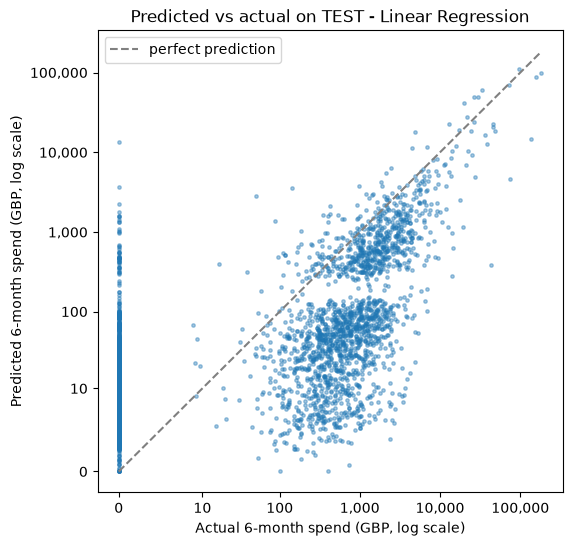

In [7]:
sm.plot_predicted_vs_actual(y_test, final_pred, final_name);

**What it shows:** Customers who spent 0 (the column on the left) get predictions from 0 up to about 13,000 GBP, mostly below 1,000. Real spenders form **two bands**: one band lies close to the diagonal (predicted roughly 300-3,000 GBP), but a large second band is predicted only about 5-200 GBP while they really spent 100-10,000 GBP. That lower band is the main reason the mean prediction is far too low. The model gets the order of magnitude right for the biggest customers, but it is not precise for individuals.

## 6. Save the final spend model

In [8]:
smearing = factors[final_name.replace(' + smearing', '')] if final_name.endswith('+ smearing') else 1.0
sm.save_spend_model(fitted[final_name.replace(' + smearing', '')], final_name, list(X_train.columns), smearing, cap)
print('Saved', config.SPEND_MODEL, '| smearing factor used:', smearing, '| cap:', cap)

Saved D:\SEM-7\churn-clv-predictor\models\spend_model.pkl | smearing factor used: 1.0 | cap: 110155.12


**Phase 6 spend model (single model): Linear Regression on log1p(future_spend), no smearing, capped at the TRAIN maximum.** Chosen by the lowest CV RMSE in GBP on TRAIN. Honest assessment: the spend predictions are **weak**. Test R-squared 0.616 in GBP sounds acceptable but is driven by a few very large customers; the typical error for a spender (MAE 1,397 GBP) is several times the median spend, predictions are about 55% too low on average (645 vs 1,444), and a one-line historical-rate baseline does better on TEST in GBP. Use the predicted value as a rough ranking of customer value, not as an exact GBP amount.

*Update:* this model is **replaced** by the two-part model in section 7, because the two-part model has a lower CV RMSE in GBP on TRAIN.

## 7. Phase 6b: two-part (hurdle) spend model
About half of the customers spend 0. A single log regression has to fit the zeros and the spenders with one line, which drags the spenders' predictions down (the low band in the plot above). The two-part model splits it:
- **Part 1:** classifier for P(future_spend > 0). Logistic Regression vs XGBoost, chosen by CV ROC-AUC on TRAIN.
- **Part 2:** regression on log1p(future_spend), trained **only on TRAIN customers who spent**. Linear Regression vs XGBoost, chosen by CV RMSE in GBP on TRAIN spenders, with Duan's smearing learned on TRAIN spenders only.
- **Expected spend** = P(spend > 0) x predicted amount, capped at the TRAIN maximum.

**Rule:** the two-part model replaces the Phase 6 model ONLY if its CV RMSE in GBP on TRAIN is lower. TEST is not used to decide.

In [9]:
import numpy as np
import hurdle_model as hm

y_train_gbp = train['future_spend'].to_numpy()
spenders = y_train_gbp > 0
print(f'TRAIN spenders: {spenders.sum():,} of {len(spenders):,} ({spenders.mean():.1%})')

part1_table, classifiers = hm.evaluate_part1(X_train, spenders.astype(int))
part1_table.round(3)

TRAIN spenders: 1,869 of 3,465 (53.9%)


,part,model,cv_roc_auc,best_params
0,1: P(spend > 0),Logistic/Linear,0.772,
1,1: P(spend > 0),XGBoost,0.768,"{'max_depth': 2, 'learning_rate': 0.03, 'n_est..."


In [10]:
part2_table, regressors = hm.evaluate_part2(X_train[spenders], np.log1p(y_train_gbp[spenders]))
part2_table.round(3)

,part,model,cv_rmse_gbp,cv_mae_gbp,cv_r2_gbp,cv_mean_predicted,cv_mean_actual,mean_smearing_factor,best_params
0,2: amount | spend > 0,Logistic/Linear,3130.024,902.299,0.562,1774.388,1471.213,1.640,
1,2: amount | spend > 0,XGBoost,3283.847,817.205,0.518,1384.508,1471.213,1.309,"{'max_depth': 3, 'learning_rate': 0.03, 'n_est..."


In [11]:
part1_name, part2_name = hm.choose_parts(part1_table, part2_table)
print('Part 1 (highest CV ROC-AUC):', part1_name)
print('Part 2 (lowest CV RMSE in GBP on spenders):', part2_name)

Part 1 (highest CV ROC-AUC): Logistic/Linear
Part 2 (lowest CV RMSE in GBP on spenders): Logistic/Linear


**Chosen parts (TRAIN only):** Part 1 = **Logistic Regression** (CV ROC-AUC 0.772 vs 0.768 for XGBoost). Part 2 = **Linear Regression** (CV RMSE in GBP on spenders 3,130 vs 3,284 for XGBoost). The smearing factor learned on spenders is about **1.6** (1.64 averaged over CV folds, 1.65 on all TRAIN spenders), much closer to 1 than the factor of about 18 for the single model, because once the zeros are removed the log errors are much smaller.

### Whole two-part model vs Phase 6 model on TRAIN CV (GBP)

In [12]:
rows = []
for c_name in hm.PART_NAMES:
    for r_name in hm.PART_NAMES:
        label = f'Two-part: {c_name} + {r_name}' + ('  <- chosen parts' if (c_name, r_name) == (part1_name, part2_name) else '')
        rows.append({'model': label, **hm.cross_validate_hurdle(classifiers[c_name], regressors[r_name], X_train, y_train_gbp)})
reference = cv_table[cv_table['model'].isin(['Linear Regression', 'Historical-rate baseline'])]
reference = reference[['model', 'cv_rmse_gbp', 'cv_mae_gbp', 'cv_r2_gbp', 'cv_mean_predicted']]
hurdle_cv = pd.concat([reference, pd.DataFrame(rows)], ignore_index=True)
hurdle_cv['cv_mean_actual'] = y_train_gbp.mean()
hurdle_cv.to_csv(config.TABLES_DIR / 'spend_two_part_cv_train.csv', index=False)
hurdle_cv.round(3)

,model,cv_rmse_gbp,cv_mae_gbp,cv_r2_gbp,cv_mean_predicted,cv_mean_actual
0,Historical-rate baseline,3989.644,1373.902,-0.263,1981.182,793.564
1,Linear Regression,2830.111,621.813,0.364,424.790,793.564
2,Two-part: Logistic/Linear + Logistic/Linear <...,2408.045,623.096,0.540,963.091,793.564
3,Two-part: Logistic/Linear + XGBoost,2335.239,563.417,0.567,742.564,793.564
4,Two-part: XGBoost + Logistic/Linear,2358.197,615.439,0.559,943.496,793.564
5,Two-part: XGBoost + XGBoost,2367.191,565.998,0.555,728.797,793.564


In [13]:
chosen_cv = hurdle_cv[hurdle_cv['model'].str.contains('chosen parts')].iloc[0]
plain_cv = hurdle_cv[hurdle_cv['model'] == 'Linear Regression'].iloc[0]
replace = chosen_cv['cv_rmse_gbp'] < plain_cv['cv_rmse_gbp']
print(f"Two-part CV RMSE (GBP): {chosen_cv['cv_rmse_gbp']:,.1f}   Plain Linear Regression: {plain_cv['cv_rmse_gbp']:,.1f}")
print('Replace the Phase 6 spend model:', replace)

Two-part CV RMSE (GBP): 2,408.0   Plain Linear Regression: 2,830.1
Replace the Phase 6 spend model: True


**Decision (TRAIN CV only): replace.** The chosen two-part model has CV RMSE 2,408 GBP and CV R-squared 0.540, vs 2,830 GBP and 0.364 for the Phase 6 Linear Regression. Its CV mean prediction is 963 GBP vs an actual 794 GBP, so on TRAIN it now predicts a bit **too high** (+21%), instead of far too low. Honest note: the combination Logistic + XGBoost has an even lower combined CV RMSE (2,335), but the rule agreed beforehand picks each part by its own CV score, so we keep Logistic + Linear. The difference is small (about 3%).

### Test results (reported only, not used to decide)

In [14]:
hurdle = hm.fit_hurdle(classifiers[part1_name], regressors[part2_name], X_train, y_train_gbp)
print(f"Smearing factor (TRAIN spenders): {hurdle['smearing_factor']:.3f}   (single model earlier: {factors['Linear Regression']:.1f})")
hurdle_test, hurdle_predictions = hm.test_comparison(hurdle, fitted['Linear Regression'], X_test, y_test, test, cap)
sm.check_leakage_alarm(hurdle_test)
hurdle_test.to_csv(config.TABLES_DIR / 'spend_two_part_test.csv', index=False)
hurdle_test.round(3)

Smearing factor (TRAIN spenders): 1.652   (single model earlier: 17.9)
Leakage alarm check: no row above test R2 0.9 (max 0.772)


,model,n_capped,mae,rmse,r2,mae_spenders_only,r2_log_scale,mean_predicted,mean_actual,max_predicted,max_actual
0,Two-part model,1,849.349,3440.426,0.738,1017.644,0.065,1303.160,1444.314,110155.120,183529.65
1,Plain Linear Regression (Phase 6 final),1,1005.588,4169.478,0.616,1397.371,0.262,645.385,1444.314,110155.120,183529.65
2,Historical-rate baseline,0,1042.424,3212.441,0.772,1055.221,-0.228,1777.996,1444.314,128514.098,183529.65


**Test results:** The two-part model clearly improves on the Phase 6 model: MAE 849 vs 1,006 GBP, RMSE 3,440 vs 4,169 GBP, R-squared 0.738 vs 0.616, MAE for spenders 1,018 vs 1,397 GBP, and mean prediction 1,303 vs 645 GBP (actual 1,444). It now also has a lower MAE than the historical-rate baseline (849 vs 1,042, and 1,018 vs 1,055 for spenders), but **the baseline still has the best RMSE and R-squared on TEST** (3,212 and 0.772); as before, that baseline was the worst on TRAIN. The log-scale R-squared drops to 0.07 because the expected value never reaches 0: a customer who will not buy still gets P(spend) x amount, typically a few hundred GBP.

**Season mismatch:** it still causes under-prediction. On TRAIN CV the model predicts 21% too high (963 vs 794), but on TEST it predicts 10% too low (1,303 vs 1,444). The model learned spending levels from a Dec-May window; the Jun-Nov test window includes the autumn peak.

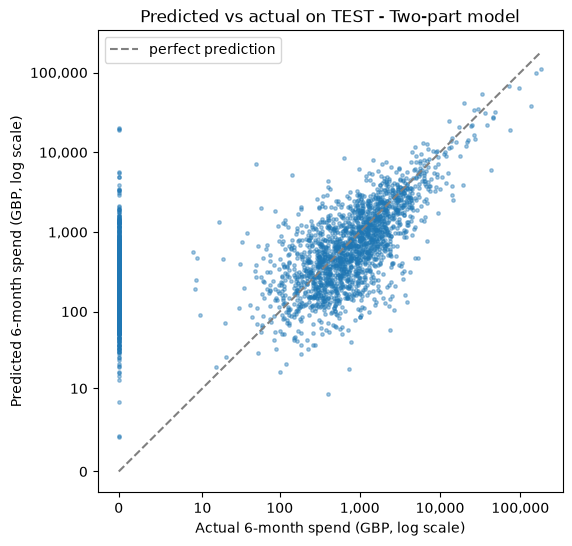

In [15]:
plot_name = 'Two-part model' if replace else final_name
plot_pred = hurdle_predictions['Two-part model'] if replace else final_pred
sm.plot_predicted_vs_actual(y_test, plot_pred, plot_name, 'spend_predicted_vs_actual_two_part');

**What it shows:** The low band of badly under-predicted spenders from the single model is gone; real spenders now lie around the diagonal, mostly within a factor of about 3 either way. Customers who spent 0 (left column) all get a positive expected value, mostly 100-1,000 GBP, a few up to about 20,000 GBP.

In [16]:
if replace:
    hm.save_hurdle_model(hurdle, list(X_train.columns), cap, f'{part1_name} + {part2_name}')
    print('Saved two-part model to', config.SPEND_MODEL)
else:
    print('Kept the Phase 6 model in', config.SPEND_MODEL)

Saved two-part model to D:\SEM-7\churn-clv-predictor\models\spend_model.pkl


**Final spend model: two-part model (Logistic Regression for P(spend > 0) x Linear Regression amount with smearing 1.65), capped at the TRAIN maximum (110,155 GBP).** Saved to `models/spend_model.pkl`. It was chosen by TRAIN CV in GBP only. Honest summary: it is clearly better than the single log model, and its average level is now close to reality (-10% on TEST), but individual errors are still large (MAE about 850 GBP vs a median test spend of 407 GBP), and on TEST RMSE / R-squared a one-line historical-rate baseline is still better, partly for seasonal reasons. Use the predicted value as a rough estimate.